# CS781 Phase 4 — Court Judgment Prediction — Arch 3: Encoder/decoder hybrid (Prefix-LM) (`ARCH = "prefixlm"`)
Adapts **your Phase-1 checkpoint** `P1_REPOS[ARCH]` (`best/`; bart = the v2 retrain) to court judgment prediction:
one binary outcome (0 / 1) per long case document, scored by macro-F1 over both classes.

| | |
|---|---|
| Backbone | Phase-1 prefix-LM `LlamaModel`, whole chunk as the bidirectional prefix by default (`ATTN`) |
| Long documents | the document's tokens are cut into chunks of `CHUNK_LEN` tokens starting every `CHUNK_STRIDE` tokens (overlap when `CHUNK_STRIDE < CHUNK_LEN`); a document with more than `MAX_CHUNKS` (training) / `MAX_CHUNKS_PRED` (prediction) chunks is represented by the chunks `CHUNK_SELECT` picks: `first`, `last`, `first_last` (half from each end), `even` (evenly spaced over the whole document), `random` (a fresh random subset each time a document is trained on; `even` at prediction) |
| Chunk vector | token states of a chunk pooled by `POOL` (`mean` / `first` / `last`); chunks are encoded independently |
| Document vector (`DOC_POOL`) | `mean`, `max`, `attn` (learned attention over the chunks), `gru` (BiGRU over the chunk sequence); optional learned embedding of each chunk's relative position in the document (`CHUNK_POS`) |
| Head (`HEAD`) | `linear` or `mlp` -> 2 logits; prediction `p(1) >= THRESHOLD` (0.5, or the threshold that maximises dev macro-F1) |
| Methods (`METHOD`) | `full`, `partial` (top blocks only), `unfreeze` (gradual unfreezing), `bitfit`, `lorma` (LoRMA), `adalora` (AdaLoRA), `adapter` (bottleneck adapters), `kd` (distillation into a smaller student) |
| Outputs | `submission_<RUN_NAME>.zip` + run files (scores, per-document dev details, test predictions, per-document scores for distillation) in private repo `<hf-user>/cs781-p4` under `runs/<RUN_NAME>/` |

**Before you start**
1. Runtime -> Change runtime type -> **T4 GPU**.
2. Secrets (key icon) -> `HF` = the **same** HF token as Phases 1–3 (reads your `cs781-p1-*` repos and the gated course
   dataset, writes `cs781-p4`).
3. Choose `METHOD`, `CHUNK_SELECT`, `DOC_POOL` in the first code cell, check *Configuration*, then **Run all**.

Another experiment on the same account: change the first cell (the run name follows), **Run all** again — every run
starts from the Phase-1 checkpoint; tokenised documents are cached in the runtime, so a second run skips tokenisation.
`kd` needs a finished teacher run in `cs781-p4` (`TEACHER_RUN`, any architecture: the student learns from the
per-document scores the teacher run saved for the training documents it was trained on).

Phase-4 rules (capstone §1, §10.2): ≥6 submissions; all four Phase-1 models used and the best four submissions from
different Phase-1 models; ≥4 substantially different experiments, of which ≥3 use different techniques **from the
§10.2.1 list** (full, partial / layer-wise, layer freezing / unfreezing, BitFit, LoRMA, AdaLoRA, adapters, KD) with
**LoRMA compulsory**, and ≥1 is knowledge distillation; runs that differ only in hyperparameters do not count, and a
different head or pooling with the same method is not a different technique.

In [1]:
ARCH = "prefixlm"                 # fixed for this notebook
METHOD = "lorma"                  # "full" | "partial" | "unfreeze" | "bitfit" | "lorma" | "adalora" | "adapter" | "kd"
CHUNK_SELECT = "even"             # "first" | "last" | "first_last" | "even" | "random"
DOC_POOL = "mean"                 # "mean" | "max" | "attn" | "gru"
RUN_NAME = f"{ARCH}_{METHOD}_{CHUNK_SELECT}_{DOC_POOL}"   # unique per experiment (add a suffix when other settings change)

In [2]:
import os, json, math, time, random, zipfile, gc, hashlib
from collections import Counter
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from huggingface_hub import login, whoami, HfApi, hf_hub_download, snapshot_download
from sklearn.metrics import f1_score, precision_score, recall_score, confusion_matrix

def get_hf_token():
    try:
        from google.colab import userdata
        return userdata.get("HF")
    except Exception:
        pass
    try:
        from kaggle_secrets import UserSecretsClient
        return UserSecretsClient().get_secret("HF")
    except Exception:
        return os.environ["HF_TOKEN"]

HF_TOKEN = get_hf_token()
os.environ["HF_TOKEN"] = HF_TOKEN
login(token=HF_TOKEN)
HF_USER = whoami(token=HF_TOKEN)["name"]
api = HfApi(token=HF_TOKEN)

def hub_push(fn, what, tries=3):
    for t in range(1, tries + 1):
        try:
            fn(); return True
        except Exception as e:
            print(f"  !! {what} upload failed ({t}/{tries}): {e!r}")
            time.sleep(30 * t)
    return False

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
assert DEVICE == "cuda" or os.environ.get("CS781_ALLOW_CPU"), "Switch the runtime to a GPU"
AMP = DEVICE == "cuda"
print(torch.__version__, torch.cuda.get_device_name(0) if AMP else "CPU")
import transformers; print("transformers", transformers.__version__)

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


2.11.0+cu130 Tesla T4
transformers 5.20.1


## Configuration — **all values below are YOUR CHOICE** (document them in the report)
The numbers filled in are placeholders that make the notebook run end to end on a T4, not tuned values.

In [3]:
DATASET = "Exploration-Lab/CS-781-Capstone"
# Phase-1 checkpoint (best/) per architecture; bart = the v2 retrain (v1 `cs781-p1-bart` collapsed, never use it)
P1_REPOS = {"llama": f"{HF_USER}/cs781-p1-llama", "bart": f"{HF_USER}/cs781-p1-bart-v2",
            "prefixlm": f"{HF_USER}/cs781-p1-prefixlm", "mistral_swa": f"{HF_USER}/cs781-p1-mistral_swa"}
P4_REPO = f"{HF_USER}/cs781-p4"             # all Phase-4 runs: runs/<RUN_NAME>/...
WORK = "/content/p4" if os.path.isdir("/content") else "/tmp/p4"
RUN_DIR = f"{WORK}/{RUN_NAME}"
CACHE_DIR = f"{WORK}/cache"                 # tokenised documents, reused by later runs in the same runtime
os.makedirs(RUN_DIR, exist_ok=True); os.makedirs(CACHE_DIR, exist_ok=True)

SEED = 42
TRAIN_MAX_DOCS = None      # None = every train.json document; else a label-stratified random subset of this many
                           # (tokenisation time / RAM grow with it; MAX_TRAIN_MINUTES bounds training either way)

# Long documents -> chunks -> document vector
CHUNK_LEN = 512            # tokens per chunk (Phase-1 positions: 1024; the bart encoder was pretrained on <= 768 tokens)
CHUNK_STRIDE = 512         # tokens between consecutive chunk starts (< CHUNK_LEN: overlapping chunks)
MAX_CHUNKS = 8             # chunks per document in training (CHUNK_SELECT picks them when a document has more)
MAX_CHUNKS_PRED = 8        # chunks per document at prediction (dev / test / distillation scores)
POOL = "mean"              # token states -> chunk vector: "mean" | "first" | "last"
CHUNK_POS = False          # add a learned embedding of the chunk's relative position in the document (POS_BUCKETS bins)
POS_BUCKETS = 8
ATT_HIDDEN = 256           # DOC_POOL "attn": hidden size of the attention scorer
GRU_HIDDEN = 256           # DOC_POOL "gru": hidden size per direction
HEAD = "linear"            # "linear" | "mlp" (Linear -> tanh -> dropout -> Linear)
HEAD_HIDDEN = 256

# How the backbone attends inside a chunk
#   decoder-only models: "causal" (as pretrained) or "bidirectional" (full mask; for mistral_swa a ±window band)
ATTN = {"llama": "causal", "prefixlm": "bidirectional", "mistral_swa": "causal", "bart": "n/a"}[ARCH]
#   bart: "encoder" = encoder states only; "decoder" = chunk fed to encoder AND decoder, decoder states
BART_MODE = "encoder"

# Optimisation
EPOCHS = 2                 # passes over the training documents (MAX_TRAIN_MINUTES may end training first)
MAX_TRAIN_MINUTES = 60     # cap on training time, dev evaluations excluded; the LR, unfreezing and AdaLoRA schedules
                           # follow max(fraction of steps, fraction of this time), so they complete by the cap
EVAL_EVERY_MINUTES = 12    # dev evaluation after this many training minutes (and at the end of every epoch)
PATIENCE = 3               # dev evaluations without a macro-F1 improvement before stopping
BATCH_DOCS = 2             # documents per forward pass (each up to MAX_CHUNKS chunks)
GRAD_ACCUM = 4             # forward passes per optimizer step: effective batch = BATCH_DOCS * GRAD_ACCUM documents
PRED_BATCH_DOCS = 8        # documents per forward pass at prediction
GRAD_CKPT = False          # activation checkpointing in the backbone (less GPU memory, slower)
LR = {"full": 2e-5, "partial": 5e-5, "unfreeze": 5e-5, "bitfit": 1e-3, "lorma": 5e-4, "adalora": 5e-4,
      "adapter": 5e-4, "kd": 5e-5}[METHOD]
HEAD_LR = 1e-3             # head, document pooling, chunk-position embedding
LAYER_LR_DECAY = 1.0       # backbone LR x LAYER_LR_DECAY per block below the top (embeddings lowest); 1.0 = off
WEIGHT_DECAY = 0.01
WARMUP_FRAC = 0.06
GRAD_CLIP = 1.0
DROPOUT = 0.1              # on the document vector (and inside the mlp head)
CLASS_WEIGHTS = "none"     # "none" | "inverse" | "inverse_sqrt": per-class loss weights from training label counts
THRESHOLD = 0.5            # predict 1 when p(1) >= THRESHOLD;  "dev" = the threshold that maximises dev macro-F1 at the
                           # best checkpoint (then the dev score is measured on the data the threshold was fitted to)

# Method-specific
PARTIAL_TOP = 4                         # partial: top blocks (+ final norm) trained, the rest of the backbone frozen
UNFREEZE_FRAC = 0.5                     # unfreeze: head only at first, then one more block from the top at equal
                                        # intervals; every block trainable from this fraction of training on
UNFREEZE_EMBED = False                  # unfreeze: embeddings join as the last group
BITFIT_ADD_BIAS = True                  # bitfit: bias-free nn.Linear layers (llama / mistral) get a zero bias to train
ADAPT_TARGETS = ["q_proj", "v_proj"]    # lorma / adalora: names of the nn.Linear layers that get adapters
RANK, ALPHA = 8, 16                     # lorma: rank, scale alpha/r
LORMA_VARIANT = "plus"                  # "plus" = additive-identity rank inflation, "pi" = permutation inflation
ADALORA_INIT_R, ADALORA_TARGET_R = 12, 4  # adalora: initial / final average rank per adapted layer (scale ALPHA/INIT_R)
ADALORA_TINIT, ADALORA_TFINAL = 0.1, 0.2  # adalora: fraction of training before pruning / with the final budget fixed
ADALORA_DELTA_T = 10                    # adalora: optimizer steps between rank reallocations
ADALORA_BETAS = (0.85, 0.85)            # adalora: EMA factors of sensitivity / uncertainty
ADALORA_ORTH = 0.1                      # adalora: weight of the orthogonality regulariser on P and Q
ADAPTER_AT = ["o_proj", "down_proj", "out_proj", "fc2"]   # adapter: after these projections (attention / FFN outputs)
ADAPTER_DIM = 64                        # adapter: bottleneck size
ADAPTER_TRAIN_NORMS = True              # adapter: layer norms trained too (as in Houlsby et al.)

# Knowledge distillation (METHOD == "kd"); the student is this notebook's ARCH with fewer Phase-1 blocks
TEACHER_RUN = "llama_full_even_mean"    # a finished run in P4_REPO (it saved train_scores.json)
STUDENT_LAYERS = None                   # None = every 2nd block (per stack for bart), or an explicit list
KD_T = 2.0
KD_ALPHA = 0.5                          # loss = KD_ALPHA * task loss + (1 - KD_ALPHA) * T^2 * KL(teacher || student)

SAVE_TRAIN_SCORES = True   # per-document scores for the training documents this run trained on, so a later kd run can
                           # use this run as teacher (costs one prediction pass over those documents)
TRAIN_SCORES_MAX_DOCS = 10000   # None = every document seen in training; else a random subset of them of this size
                                # (a kd student trains on exactly the scored documents)
SAVE_WEIGHTS = False       # fine-tuned weights to the Hub (not needed for distillation)

METHODS = ("full", "partial", "unfreeze", "bitfit", "lorma", "adalora", "adapter", "kd")
assert METHOD in METHODS, METHOD
assert CHUNK_SELECT in ("first", "last", "first_last", "even", "random") and DOC_POOL in ("mean", "max", "attn", "gru")
assert POOL in ("mean", "first", "last") and HEAD in ("linear", "mlp")
assert CLASS_WEIGHTS in ("none", "inverse", "inverse_sqrt") and 0 < UNFREEZE_FRAC <= 1
assert 0 < CHUNK_STRIDE <= CHUNK_LEN and MAX_CHUNKS >= 1 and MAX_CHUNKS_PRED >= 1
assert THRESHOLD == "dev" or 0 < THRESHOLD < 1
assert 0 <= ADALORA_TINIT and ADALORA_TINIT + ADALORA_TFINAL < 1 and ADALORA_TARGET_R <= ADALORA_INIT_R

def finished_runs():
    """Runs in P4_REPO that completed with distillation scores (a run uploads runs/<RUN_NAME>/ at the end)."""
    try:
        files = api.list_repo_files(P4_REPO)
    except Exception:                                # repo does not exist yet
        return []
    return sorted({f.split("/")[1] for f in files if f.startswith("runs/") and f.endswith("/train_scores.json")})

if METHOD == "kd" and TEACHER_RUN not in (_done := finished_runs()):
    raise RuntimeError(f"TEACHER_RUN = {TEACHER_RUN!r} is not a finished run in {P4_REPO}. Set TEACHER_RUN to one of "
                       f"these finished runs: {_done or 'none yet -- let a non-kd run finish first'}")
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

## Data: download, inspect, parse
The raw first record of each file is printed so the format can be checked by eye. train / dev records carry `id`,
`text`, `label` (0 / 1); test records `id`, `text`. A repeated ID inside a file is dropped (first kept) and counted.
Documents with identical text in two splits are counted — a measurement only, nothing is removed.

In [4]:
def fetch(rel):
    return hf_hub_download(DATASET, f"Phase_4_CJPE/{rel}", repo_type="dataset", token=HF_TOKEN)

def read_json_any(path):
    txt = open(path, encoding="utf-8").read()
    try:
        return json.loads(txt)
    except json.JSONDecodeError:                       # JSON Lines
        return [json.loads(l) for l in txt.splitlines() if l.strip()]

def as_records(raw, name):
    """-> [(id, text, label or None)] from a list of {id, text, label} records or a dict id -> record."""
    items = raw.items() if isinstance(raw, dict) else [(r.get("id"), r) for r in raw]
    out = []
    for k, v in items:
        text = v if isinstance(v, str) else v.get("text")
        lab = None if isinstance(v, str) else next((v[f] for f in ("label", "gold") if f in v), None)
        if isinstance(text, list):
            text = "\n".join(map(str, text))
        assert k is not None and isinstance(text, str), f"{name}: unexpected record {repr(v)[:200]}"
        if lab is not None:
            assert str(lab).strip() in ("0", "1"), f"{name}: label {lab!r} of {k} is not 0 / 1"
            lab = int(str(lab).strip())
        out.append((str(k), text, lab))
    return out

FILES = {"train": "Train/train.json", "dev": "Train/dev.json", "test": "Test/test.json"}
IDS, TEXT, LABEL = {}, {}, {}          # IDS[split]: ids in file order;  TEXT / LABEL keyed by (split, id)
for split, rel in FILES.items():
    t0 = time.time(); raw = read_json_any(fetch(rel))
    first = raw[next(iter(raw))] if isinstance(raw, dict) else raw[0]
    print(f"{rel}: {type(raw).__name__} of {len(raw)} ({time.time()-t0:.0f}s)  first record: {repr(first)[:300]}")
    recs = as_records(raw, rel); del raw
    ids, dup, conflict = [], 0, 0
    for k, text, lab in recs:
        key = (split, k)
        if key in TEXT:
            dup += 1; conflict += LABEL.get(key) != lab
            continue
        if split != "test":
            assert lab is not None, f"{rel}: record {k} has no label"
            LABEL[key] = lab
        ids.append(k); TEXT[key] = text
    IDS[split] = ids
    del recs; gc.collect()
    if dup:
        print(f"  !! {dup} repeated ids dropped (first kept; {conflict} of them with a different label)")

print(f"\n{'split':6s} {'docs':>6s} {'label 0':>8s} {'label 1':>8s} {'chars median':>12s} {'p90':>9s} {'max':>9s} {'empty':>6s}")
for split, ids in IDS.items():
    ch = np.array([len(TEXT[(split, k)]) for k in ids])
    c = Counter(LABEL[(split, k)] for k in ids) if split != "test" else {}
    print(f"{split:6s} {len(ids):6d} {c.get(0, '-'):>8} {c.get(1, '-'):>8} {int(np.median(ch)):12d} "
          f"{int(np.percentile(ch, 90)):9d} {ch.max():9d} {(ch == 0).sum():6d}")
HASH = {s: {hashlib.md5(TEXT[(s, k)].encode()).hexdigest() for k in ids} for s, ids in IDS.items()}
print(f"documents with identical text in two splits: train&dev {len(HASH['train'] & HASH['dev'])}  "
      f"train&test {len(HASH['train'] & HASH['test'])}  dev&test {len(HASH['dev'] & HASH['test'])}")
del HASH

TRAIN_IDS = list(IDS["train"])
if TRAIN_MAX_DOCS and TRAIN_MAX_DOCS < len(TRAIN_IDS):
    rng = np.random.default_rng(SEED); keep = set()
    for c in (0, 1):
        pool = [k for k in TRAIN_IDS if LABEL[("train", k)] == c]
        n_c = round(TRAIN_MAX_DOCS * len(pool) / len(TRAIN_IDS))
        keep |= {pool[i] for i in rng.choice(len(pool), size=n_c, replace=False)}
    TRAIN_IDS = [k for k in TRAIN_IDS if k in keep]
    print(f"training subset: {len(TRAIN_IDS)} of {len(IDS['train'])} documents (label-stratified, seed {SEED})")
DEV_IDS, TEST_IDS = IDS["dev"], IDS["test"]

Phase_4_CJPE/Train/train.json: reconstructing file:   0%|          |  0.00B /  737MB            

Phase_4_CJPE/Train/train.json: downloading bytes:           |  0.00B            

Train/train.json: list of 37387 (12s)  first record: {'id': '2020_1', 'text': ' Uday Umesh Lalit, J. These appeals arise out of the Judgment and Order dated 09.12.2015 passed by the Division Bench of the High Court 1 dismissing S.T. No.192 of 2014 and other companynected matters and thereby affirming the decision of the Single Judge of the High Court 
  !! 5082 repeated ids dropped (first kept; 0 of them with a different label)


Phase_4_CJPE/Train/dev.json: reconstructing file:   0%|          |  0.00B / 45.0MB            

Phase_4_CJPE/Train/dev.json: downloading bytes:           |  0.00B            

Train/dev.json: list of 1988 (2s)  first record: {'id': '1989_75', 'text': 'civil appellate jurisdiction civil appeal number 1709\nof\n1988.\nfrom the judgment and order dated 9.10.1987 of t\nhe\ncentral administrative tribunal chandigarh in appln. t.\n--\n1055 of 1986.\nwith\n slp  civil  number 6998 of 1988 \n\nc. mahajan mrs. indu goswami c.v. 
  !! 994 repeated ids dropped (first kept; 0 of them with a different label)


Phase_4_CJPE/Test/test.json: reconstructing file:   0%|          |  0.00B / 35.3MB            

Phase_4_CJPE/Test/test.json: downloading bytes:           |  0.00B            

Test/test.json: list of 1517 (2s)  first record: {'id': '1986_397', 'text': 'civil appellate jurisdiction civil appeal number 1257\n nl  of 1985.\nfrom the judgment and order dated 24th january 1985 of\nthe patna high companyrt in civil writ jurisdiction number 5877 of\n1983.\n\nk. banerjee sol. genl d.n. misra b.d. barucha and\n\nm. dittia for th

split    docs  label 0  label 1 chars median       p90       max  empty
train   32305    18920    13385        12120     38371   2492701      0
dev       994      497      497        16700     40429    260198      0
test     1517        -        -        17320     42859    233000      0
documents with identical text in two splits: train&dev 0  train&test 0  dev&test 0


## Knowledge-distillation targets (only when `METHOD == "kd"`)
The teacher run saved `train_scores.json`: per training document it trained on, the log-probabilities of the two
classes (computed like test predictions). The student trains on exactly those documents and matches
`softmax(teacher scores / KD_T)`.

In [5]:
TEACHER, teacher_info = None, None
if METHOD == "kd":
    teacher_info = json.load(open(hf_hub_download(P4_REPO, f"runs/{TEACHER_RUN}/run_config.json", token=HF_TOKEN,
                                                  force_download=True)))
    ts = json.load(open(hf_hub_download(P4_REPO, f"runs/{TEACHER_RUN}/train_scores.json", token=HF_TOKEN,
                                        force_download=True)))
    n_before = len(TRAIN_IDS)
    TRAIN_IDS = [k for k in TRAIN_IDS if k in ts]
    assert TRAIN_IDS, "the teacher has scores for none of this run's training documents"
    TEACHER = {("train", k): torch.tensor(ts[k], dtype=torch.float32) for k in TRAIN_IDS}
    assert all(t.shape == (2,) for t in TEACHER.values())
    tv = teacher_info["dev"]
    print(f"teacher {TEACHER_RUN}: {teacher_info['arch']}/{teacher_info['method']}, {teacher_info['params_final']/1e6:.1f}M "
          f"params, dev macro-F1 {tv['F1']:.4f}, dev inference {teacher_info['dev_predict_seconds']:.1f}s;  "
          f"student trains on the {len(TRAIN_IDS)} of {n_before} training documents the teacher scored")
    del ts
_used = set(TRAIN_IDS)
for key in [k for k in TEXT if k[0] == "train" and k[1] not in _used]:     # free the text of unused training documents
    del TEXT[key]
gc.collect()

0

## Tokenizer and document tokens
Each document is tokenised as a whole (no special tokens) and stored as `uint16` ids; an empty document becomes a single
`<|endoftext|>`. Tokenised documents are cached in `CACHE_DIR`, keyed by the tokenizer file.

In [6]:
from transformers import PreTrainedTokenizerFast

P1_DIRS = {}
def p1_dir(arch):
    if arch not in P1_DIRS:
        try:
            path = snapshot_download(P1_REPOS[arch], token=HF_TOKEN, allow_patterns=["best/*"])
        except Exception as e:
            raise RuntimeError(f"cannot read {P1_REPOS[arch]}/best -- has its Phase-1 notebook finished? ({e!r})")
        P1_DIRS[arch] = os.path.join(path, "best")
    return P1_DIRS[arch]

tokenizer = PreTrainedTokenizerFast.from_pretrained(p1_dir(ARCH))
tokenizer.model_max_length = 10**9
PAD_ID, EOS_ID, VOCAB = tokenizer.pad_token_id, tokenizer.eos_token_id, len(tokenizer)
assert VOCAB <= 65535, "token ids are stored as uint16"
TOK_FP = hashlib.md5(open(os.path.join(p1_dir(ARCH), "tokenizer.json"), "rb").read()).hexdigest()[:12]

def tokenize_split(split, ids, bs=256):
    path = f"{CACHE_DIR}/{split}_{TOK_FP}.npz"
    have = {}
    if os.path.exists(path):
        z = np.load(path)
        offs, flat = z["offsets"], z["flat"]
        have = {k: flat[offs[i]:offs[i + 1]] for i, k in enumerate(z["ids"].tolist())}
    need = [k for k in ids if k not in have]
    t0 = time.time()
    for i in range(0, len(need), bs):
        part = need[i:i + bs]
        enc = tokenizer([TEXT[(split, k)] for k in part], add_special_tokens=False)["input_ids"]
        for k, x in zip(part, enc):
            have[k] = np.asarray(x, dtype=np.uint16)
        if (i // bs) % 20 == 19:
            print(f"  {split}: {i + len(part)}/{len(need)} documents tokenised ({time.time()-t0:.0f}s)")
    if need:
        keys = list(have)
        lens = np.array([len(have[k]) for k in keys], dtype=np.int64)
        np.savez(path, ids=np.array(keys), offsets=np.concatenate([[0], np.cumsum(lens)]),
                 flat=np.concatenate([have[k] for k in keys]))
    print(f"{split}: {len(ids)} documents ({len(ids) - len(need)} from cache, {len(need)} tokenised in {time.time()-t0:.0f}s)")
    return {(split, k): have[k] if len(have[k]) else np.array([EOS_ID], dtype=np.uint16) for k in ids}

TOK = {}
for split, ids in (("train", TRAIN_IDS), ("dev", DEV_IDS), ("test", TEST_IDS)):
    TOK.update(tokenize_split(split, ids))
del TEXT; gc.collect()
TRAIN_KEYS = [("train", k) for k in TRAIN_IDS]
DEV_KEYS = [("dev", k) for k in DEV_IDS]
TEST_KEYS = [("test", k) for k in TEST_IDS]
Y = {k: v for k, v in LABEL.items() if k in TOK}
DEV_Y = np.array([Y[k] for k in DEV_KEYS])

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 6 files:   0%|          | 0/6 [00:00<?, ?it/s]

  train: 5120/32305 documents tokenised (63s)
  train: 10240/32305 documents tokenised (97s)
  train: 15360/32305 documents tokenised (134s)
  train: 20480/32305 documents tokenised (188s)
  train: 25600/32305 documents tokenised (234s)
  train: 30720/32305 documents tokenised (267s)
train: 32305 documents (0 from cache, 32305 tokenised in 278s)
dev: 994 documents (0 from cache, 994 tokenised in 11s)
test: 1517 documents (0 from cache, 1517 tokenised in 16s)


## Chunks and batches
Chunk starts are `0, CHUNK_STRIDE, 2·CHUNK_STRIDE, …`, plus a last chunk ending exactly at the document's end, so every
token is in at least one chunk. `CHUNK_SELECT` then picks at most `MAX_CHUNKS` / `MAX_CHUNKS_PRED` of them, kept in
document order. A batch holds the selected chunks of several documents as rows of one `(Q, L)` tensor.

**Checks**: chunks cover every token of every document; pooling + regrouping returns each document's own chunks in
order (verified by pooling the token ids themselves); the label of each batch row is its document's label.

In [7]:
TRAIN_RNG = np.random.default_rng(SEED)

def chunk_starts(n):
    if n <= CHUNK_LEN:
        return [0]
    s = list(range(0, n - CHUNK_LEN + 1, CHUNK_STRIDE))
    if s[-1] + CHUNK_LEN < n:
        s.append(n - CHUNK_LEN)
    return s

def select_chunks(key, k, train):
    starts = chunk_starts(len(TOK[key])); m = len(starts)
    if m <= k:
        return starts
    mode = CHUNK_SELECT if (train or CHUNK_SELECT != "random") else "even"
    if mode == "random":
        idx = np.sort(TRAIN_RNG.choice(m, size=k, replace=False))
    elif mode == "first":
        idx = range(k)
    elif mode == "last":
        idx = range(m - k, m)
    elif mode == "first_last":
        h = (k + 1) // 2; idx = list(range(h)) + list(range(m - (k - h), m))
    else:                                                          # even
        idx = np.linspace(0, m - 1, k).round().astype(int)
    return [starts[i] for i in idx]

def pos_bucket(start, length, n):
    """relative position of a chunk's centre in the document -> one of POS_BUCKETS bins"""
    return min(POS_BUCKETS - 1, int(POS_BUCKETS * (start + length / 2) / max(n, 1)))

def collate(jobs, teacher=False):
    """jobs: list of (key, chunk starts) -> dict of tensors
    ids / att (Q, L): one row per chunk;  doc / slot (Q,): row's document in the batch and its place among that
    document's chunks;  pos (Q,): relative-position bin;  y (B,): labels (-100 = none);  tsc (B, 2): teacher scores"""
    seqs, doc, slot, pos = [], [], [], []
    for i, (key, starts) in enumerate(jobs):
        t = TOK[key]
        for j, s in enumerate(starts):
            c = t[s:s + CHUNK_LEN]
            seqs.append(c); doc.append(i); slot.append(j); pos.append(pos_bucket(s, len(c), len(t)))
    Q, L = len(seqs), max(map(len, seqs))
    ids = torch.full((Q, L), PAD_ID, dtype=torch.long); att = torch.zeros((Q, L), dtype=torch.long)
    for q, c in enumerate(seqs):
        ids[q, :len(c)] = torch.from_numpy(c.astype(np.int64)); att[q, :len(c)] = 1
    out = dict(ids=ids, att=att, doc=torch.tensor(doc), slot=torch.tensor(slot), pos=torch.tensor(pos),
               y=torch.tensor([Y.get(k, -100) for k, _ in jobs]))
    if teacher:
        out["tsc"] = torch.stack([TEACHER[k] for k, _ in jobs])
    return out

def to_dev(batch):
    return {k: v.to(DEVICE) for k, v in batch.items()}

def pool_tokens(h, att):
    """(Q, L, H) token states + (Q, L) mask (real tokens first) -> (Q, H) float32 (float64 kept) chunk vectors, by POOL"""
    h = h if h.dtype == torch.float64 else h.float()
    if POOL == "mean":
        m = att[..., None].to(h.dtype)
        return (h * m).sum(1) / m.sum(1).clamp(min=1)
    if POOL == "first":
        return h[:, 0]
    return h[torch.arange(len(h), device=h.device), att.sum(1) - 1]

def group_chunks(cv, b):
    """(Q, H) chunk vectors -> (B, K, H) per document in document order + (B, K) mask of real chunks"""
    B, K = len(b["y"]), int(b["slot"].max()) + 1
    x = cv.new_zeros(B, K, cv.shape[-1]); x[b["doc"], b["slot"]] = cv
    mask = torch.zeros(B, K, dtype=torch.bool, device=cv.device); mask[b["doc"], b["slot"]] = True
    return x, mask

def covered(n, starts):
    return sum(min(n, s + CHUNK_LEN) - max(s, e) for s, e in zip(starts, [0] + [s + CHUNK_LEN for s in starts[:-1]])
               if min(n, s + CHUNK_LEN) > max(s, e))

print(f"{'split':6s} {'tokens/doc median':>17s} {'p90':>7s} {'max':>8s} {'chunks/doc median':>17s} {'max':>5s} "
      f"{'> MAX_CHUNKS_PRED':>17s} {'tokens seen at prediction':>25s}")
for name, keys in (("train", TRAIN_KEYS), ("dev", DEV_KEYS), ("test", TEST_KEYS)):
    n = np.array([len(TOK[k]) for k in keys]); m = np.array([len(chunk_starts(x)) for x in n])
    for k, x in zip(keys, n):                                      # coverage check
        st = chunk_starts(x)
        assert st[0] == 0 and st[-1] + CHUNK_LEN >= x and all(b - a <= CHUNK_LEN for a, b in zip(st, st[1:])), k
    seen = sum(covered(len(TOK[k]), select_chunks(k, MAX_CHUNKS_PRED, train=False)) for k in keys)
    print(f"{name:6s} {int(np.median(n)):17d} {int(np.percentile(n, 90)):7d} {n.max():8d} {int(np.median(m)):17d} "
          f"{m.max():5d} {(m > MAX_CHUNKS_PRED).mean():17.1%} {seen / n.sum():25.1%}")

@torch.no_grad()
def check_alignment(jobs):
    b = collate(jobs)
    cv = pool_tokens(b["ids"].double()[..., None], b["att"])                 # pooled token ids, (Q, 1)
    x, mask = group_chunks(cv.double(), b)
    for i, (key, starts) in enumerate(jobs):
        assert int(mask[i].sum()) == len(starts) and not mask[i, len(starts):].any()
        for j, s in enumerate(starts):
            c = TOK[key][s:s + CHUNK_LEN].astype(np.float64)
            want = c.mean() if POOL == "mean" else (c[0] if POOL == "first" else c[-1])
            assert abs(x[i, j, 0].item() - want) < 1e-6 * max(1.0, want), (key, j)
        assert int(b["y"][i]) == Y.get(key, -100)

rng_chk = random.Random(0)
for _ in range(20):
    check_alignment([(k, select_chunks(k, MAX_CHUNKS, train=True)) for k in rng_chk.sample(TRAIN_KEYS, min(BATCH_DOCS + 1, len(TRAIN_KEYS)))])
check_alignment([(k, select_chunks(k, MAX_CHUNKS_PRED, train=False)) for k in DEV_KEYS[:PRED_BATCH_DOCS]])
PROBE_JOBS = [(k, select_chunks(k, MAX_CHUNKS, train=False)) for k in TRAIN_KEYS[:2]]
print(f"{len(TRAIN_KEYS)} training documents -> {math.ceil(len(TRAIN_KEYS) / (BATCH_DOCS * GRAD_ACCUM))} optimizer "
      f"steps per epoch;  coverage and alignment checks passed")

split  tokens/doc median     p90      max chunks/doc median   max > MAX_CHUNKS_PRED tokens seen at prediction
train               2479    7840   497640                 5   972             28.9%                     62.8%
dev                 3806    9311    60714                 8   119             45.5%                     63.3%
test                3955    9689    56924                 8   112             47.3%                     62.2%
32305 training documents -> 4039 optimizer steps per epoch;  coverage and alignment checks passed


## Model: Phase-1 backbone -> chunk vectors -> document vector -> head
`DOC_POOL = "attn"`: score of chunk *k* = `wᵀ tanh(W c_k)`, softmax over the document's chunks, document vector = the
weighted sum (attention pooling as in hierarchical attention networks, Yang et al., 2016). `gru`: a bidirectional GRU
reads the chunk vectors in document order; the document vector is its two final states. Pooling and head run in
float32.

In [8]:
from transformers import LlamaForCausalLM, MistralForCausalLM, BartForConditionalGeneration
from torch.nn.utils.rnn import pack_padded_sequence

def block_stacks(backbone):
    """Lists of transformer blocks in forward order (bart in decoder mode: encoder blocks, then decoder blocks)."""
    if hasattr(backbone, "layers"):
        return [backbone.layers]
    return [backbone.encoder.layers, backbone.decoder.layers]

def keep_blocks(backbone, keep):
    """Student construction: keep a subset of the Phase-1 blocks (applied to every stack)."""
    stacks = []
    for owner in ([backbone] if hasattr(backbone, "layers") else [backbone.encoder, backbone.decoder]):
        idx = keep if keep is not None else list(range(0, len(owner.layers), 2))
        owner.layers = nn.ModuleList([owner.layers[i] for i in idx])
        for j, layer in enumerate(owner.layers):
            for sub in layer.modules():
                if hasattr(sub, "layer_idx"): sub.layer_idx = j
        stacks.append(idx)
    cfg = backbone.config
    if hasattr(cfg, "num_hidden_layers") and hasattr(backbone, "layers"):
        if getattr(cfg, "layer_types", None):
            cfg.layer_types = [cfg.layer_types[i] for i in stacks[0]]
        cfg.num_hidden_layers = len(stacks[0])
    return stacks

class DocPool(nn.Module):
    """(B, K, H) chunk vectors + (B, K) mask -> (B, D) document vector, (B, K) attention weights or None"""
    def __init__(self, kind, hidden):
        super().__init__()
        self.kind = kind
        if kind == "attn":
            self.score = nn.Sequential(nn.Linear(hidden, ATT_HIDDEN), nn.Tanh(), nn.Linear(ATT_HIDDEN, 1, bias=False))
        if kind == "gru":
            self.gru = nn.GRU(hidden, GRU_HIDDEN, batch_first=True, bidirectional=True)
        self.dim = 2 * GRU_HIDDEN if kind == "gru" else hidden

    def forward(self, x, mask):
        if self.kind == "mean":
            m = mask[..., None].to(x.dtype)
            return (x * m).sum(1) / m.sum(1).clamp(min=1), None
        if self.kind == "max":
            return x.masked_fill(~mask[..., None], float("-inf")).max(1).values, None
        if self.kind == "attn":
            w = self.score(x).squeeze(-1).masked_fill(~mask, float("-inf")).softmax(-1)
            return (w[..., None] * x).sum(1), w
        packed = pack_padded_sequence(x, mask.sum(1).cpu(), batch_first=True, enforce_sorted=False)
        _, h = self.gru(packed)                                       # (2, B, GRU_HIDDEN)
        return torch.cat([h[0], h[1]], -1), None

class CJPEModel(nn.Module):
    def __init__(self, arch, attn, bart_mode, layers="all"):
        super().__init__()
        self.arch, self.attn, self.bart_mode = arch, attn, bart_mode
        d = p1_dir(arch)
        if arch == "bart":
            full = BartForConditionalGeneration.from_pretrained(d).float()
            self.backbone = full.model.encoder if bart_mode == "encoder" else full.model
            hidden = full.config.d_model
        else:
            cls = MistralForCausalLM if arch == "mistral_swa" else LlamaForCausalLM
            full = cls.from_pretrained(d).float()
            self.backbone = full.model
            hidden = full.config.hidden_size
        self.max_pos = full.config.max_position_embeddings
        self.window = getattr(full.config, "sliding_window", None) if arch == "mistral_swa" else None
        self.kept = None if layers == "all" else keep_blocks(self.backbone, layers)
        self.pos_emb = nn.Embedding(POS_BUCKETS, hidden) if CHUNK_POS else None
        if self.pos_emb is not None:
            nn.init.zeros_(self.pos_emb.weight)
        self.doc_pool = DocPool(DOC_POOL, hidden)
        self.drop = nn.Dropout(DROPOUT)
        D = self.doc_pool.dim
        self.head = (nn.Linear(D, 2) if HEAD == "linear" else
                     nn.Sequential(nn.Linear(D, HEAD_HIDDEN), nn.Tanh(), nn.Dropout(DROPOUT), nn.Linear(HEAD_HIDDEN, 2)))
        self.last_w = None                                           # attention weights of the last forward ("attn")
        if GRAD_CKPT:
            self.backbone.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})

    def encode(self, ids, att):
        """(Q, L) token ids + mask -> (Q, L, H) token states"""
        if self.arch == "bart":
            if self.bart_mode == "encoder":
                return self.backbone(input_ids=ids, attention_mask=att).last_hidden_state
            return self.backbone(input_ids=ids, attention_mask=att, decoder_input_ids=ids,
                                 decoder_attention_mask=att, use_cache=False).last_hidden_state
        mask = att
        if self.attn == "bidirectional":
            Q, L = att.shape
            mask = att.bool()[:, None, None, :].expand(Q, 1, L, L)            # True = attend; pad keys off
            if self.window:
                i = torch.arange(L, device=att.device)
                mask = mask & ((i[:, None] - i[None, :]).abs() < self.window)
        return self.backbone(input_ids=ids, attention_mask=mask, use_cache=False).last_hidden_state

    def forward(self, b):
        cv = pool_tokens(self.encode(b["ids"], b["att"]), b["att"])           # (Q, H) float32
        with torch.autocast(DEVICE, enabled=False):
            if self.pos_emb is not None:
                cv = cv + self.pos_emb(b["pos"])
            x, mask = group_chunks(cv, b)
            v, self.last_w = self.doc_pool(x, mask)
            return self.head(self.drop(v))                                   # (B, 2) logits

def n_params(m, trainable=False):
    return sum(p.numel() for p in m.parameters() if p.requires_grad or not trainable)

STUDENT = METHOD == "kd"
model = CJPEModel(ARCH, ATTN, BART_MODE, layers=STUDENT_LAYERS if STUDENT else "all").to(DEVICE)
assert CHUNK_LEN <= model.max_pos, f"CHUNK_LEN exceeds the {model.max_pos} positions of the Phase-1 model"
print(f"{ARCH} CJPE model (POOL={POOL}, DOC_POOL={DOC_POOL}, HEAD={HEAD}, CHUNK_POS={CHUNK_POS}): "
      f"{n_params(model)/1e6:.1f}M parameters" + (f"  (student, kept blocks {model.kept})" if STUDENT else ""))

Loading weights:   0%|          | 0/110 [00:00<?, ?it/s]

prefixlm CJPE model (POOL=mean, DOC_POOL=mean, HEAD=linear, CHUNK_POS=False): 109.5M parameters


## Sanity checks: attention direction and padding
Inside a chunk, changing its **last** token must change the state of its **first** token only with bidirectional
attention (or the BART encoder). A document's logits must not change when a longer document joins the batch (more
padding inside chunks and more chunk slots).

In [9]:
@torch.no_grad()
def model_checks(net):
    net.eval()
    key = next((k for k in DEV_KEYS + TRAIN_KEYS if len(TOK[k]) >= 16), DEV_KEYS[0])
    ids = torch.from_numpy(TOK[key][:16].astype(np.int64))[None].to(DEVICE); att = torch.ones_like(ids)
    ids2 = ids.clone(); ids2[0, -1] = (ids2[0, -1] + 1) % VOCAB
    h1, h2 = net.encode(ids, att).float(), net.encode(ids2, att).float()
    first, last = (h1[0, 0] - h2[0, 0]).abs().max().item(), (h1[0, -1] - h2[0, -1]).abs().max().item()
    sees_right = first > 1e-4
    expect = net.arch == "bart" or net.attn == "bidirectional"
    short = min(DEV_KEYS, key=lambda k: len(TOK[k])); long_ = max(DEV_KEYS, key=lambda k: len(TOK[k]))
    j1 = [(short, select_chunks(short, MAX_CHUNKS_PRED, train=False))]
    j2 = j1 + [(long_, select_chunks(long_, MAX_CHUNKS_PRED, train=False))]
    l1, l2 = net(to_dev(collate(j1))).float(), net(to_dev(collate(j2))).float()[:1]
    pad_ok = torch.allclose(l1, l2, atol=1e-4, rtol=1e-4)
    print(f"{net.arch} (attn={net.attn}, bart_mode={net.bart_mode}): changing a chunk's last token moves its first "
          f"token's state by {first:.2e}, its own by {last:.2e} -> sees right context: {sees_right} (expected {expect}); "
          f"logits padding-invariant: {pad_ok} (max diff {(l1 - l2).abs().max().item():.1e})")
    assert last > 1e-6, "a token's state does not depend on the token"
    assert sees_right == expect, "attention is not applied as intended"
    assert pad_ok, "padding changes the document logits"
    net.train()

model_checks(model)

prefixlm (attn=bidirectional, bart_mode=encoder): changing a chunk's last token moves its first token's state by 1.53e+00, its own by 5.71e+00 -> sees right context: True (expected True); logits padding-invariant: True (max diff 6.0e-08)


## Fine-tuning / adaptation method
* **full** — every parameter trained. **kd** — every parameter of the smaller student trained.
* **partial** — the top `PARTIAL_TOP` blocks (+ final norm) and the head are trained; everything below is frozen.
* **unfreeze** — gradual unfreezing (Howard & Ruder, 2018): only the head trains at first; then the blocks are unfrozen
  one at a time from the top, at equal intervals, until all are trainable at `UNFREEZE_FRAC` of training.
  `LAYER_LR_DECAY < 1` (layer-wise learning-rate decay) can be combined with full / partial / unfreeze / kd.
* **bitfit** (Ben Zaken et al., 2022) — only bias terms (and the head) are trained. llama / mistral linear layers have
  no biases; with `BITFIT_ADD_BIAS` each gets a zero-initialised bias (the model is unchanged at initialisation).
* **lorma** (Bihany, Patel & Modi, 2025) — multiplicative low-rank update `h = 𝓘(BA)·W0 x`. `plus`:
  `𝓘(BA) = I + (α/r)·BA`, computed as `W0x + (α/r)·B(A(W0x))` (`B = 0` at init). `pi`: `𝓘(BA)` rotates row *i* of `BA`
  cyclically by *i*; init (first column of `B` = 1, `A = e₀e₀ᵀ`) gives `𝓘(BA) = I`. A bias (BART) is added afterwards.
* **adalora** (Zhang et al., 2023) — SVD-form update `h = W0 x + (α/r₀)·P diag(E) Q x` (`E = 0` at init) with an
  orthogonality penalty `‖PᵀP − I‖_F + ‖QQᵀ − I‖_F`. Every triplet (column of P, value of E, row of Q) gets an importance
  score from the smoothed sensitivity `|w·∂L/∂w|` times its uncertainty; every `ADALORA_DELTA_T` steps the lowest-scored
  triplets get `E = 0`, so the total rank follows a cubic schedule from `ADALORA_INIT_R` to `ADALORA_TARGET_R` per layer
  (on average — layers end with different ranks).
* **adapter** (Houlsby et al., 2019) — a bottleneck `y + U·gelu(D·y)` (`U = 0` at init) on the output of the
  attention and FFN output projections (`ADAPTER_AT`), before the residual addition; with `ADAPTER_TRAIN_NORMS` the
  layer norms train too.

LoRMA and AdaLoRA merge into plain `nn.Linear` weights after training (checked numerically); adapters stay as extra
modules at inference.

In [10]:
class LoRMALinear(nn.Module):
    def __init__(self, base, r, alpha, variant):
        super().__init__()
        self.base, self.variant, d = base, variant, base.out_features
        self.A = nn.Parameter(torch.zeros(r, d)); self.B = nn.Parameter(torch.zeros(d, r))
        if variant == "plus":
            self.s = alpha / r
            nn.init.kaiming_uniform_(self.A, a=math.sqrt(5))
        else:
            self.s = 1.0
            nn.init.kaiming_uniform_(self.B, a=math.sqrt(5))
            with torch.no_grad():
                self.B[:, 0] = 1.0; self.A[0, 0] = 1.0
            rot = (torch.arange(d)[None, :] - torch.arange(d)[:, None]) % d     # T[i, j] = (BA)[i, (j - i) mod d]
            self.register_buffer("rot", rot, persistent=False)

    def transform(self):                                                        # pi only: 𝓘(BA), d x d
        return torch.gather(self.B @ self.A, 1, self.rot)

    def forward(self, x):
        y0 = F.linear(x, self.base.weight)
        y = y0 + self.s * F.linear(F.linear(y0, self.A), self.B) if self.variant == "plus" \
            else F.linear(y0, self.transform())
        return y if self.base.bias is None else y + self.base.bias

    def merged(self):
        W0 = self.base.weight
        W = W0 + self.s * self.B @ (self.A @ W0) if self.variant == "plus" else self.transform() @ W0
        return W, self.base.bias

class AdaLoRALinear(nn.Module):
    def __init__(self, base, r, alpha):
        super().__init__()
        self.base, self.s = base, alpha / r
        self.P = nn.Parameter(torch.randn(base.out_features, r) * 0.02)      # left singular vectors
        self.E = nn.Parameter(torch.zeros(r))                                # singular values
        self.Q = nn.Parameter(torch.randn(r, base.in_features) * 0.02)       # right singular vectors
        self.register_buffer("mask", torch.ones(r))                          # 0 = triplet pruned at the last reallocation

    def forward(self, x):
        return self.base(x) + self.s * F.linear(F.linear(x, self.Q * self.E[:, None]), self.P)

    def orth(self):
        I = torch.eye(self.E.shape[0], device=self.E.device)
        return torch.norm(self.P.T @ self.P - I) + torch.norm(self.Q @ self.Q.T - I)

    def merged(self):
        return self.base.weight + self.s * self.P @ (self.E[:, None] * self.Q), self.base.bias

class AdapterLinear(nn.Module):
    def __init__(self, base, dim):
        super().__init__()
        self.base = base
        self.down = nn.Linear(base.out_features, dim); self.up = nn.Linear(dim, base.out_features)
        nn.init.zeros_(self.up.weight); nn.init.zeros_(self.up.bias)

    def forward(self, x):
        y = self.base(x)
        return y + self.up(F.gelu(self.down(y)))

class RankAllocator:
    """AdaLoRA budget: importance = EMA(|w·g|) · EMA(| |w·g| − EMA(|w·g|) |) per entry; a triplet's score is
    s(E_i) + mean_j s(Q_ij) + mean_j s(P_ji). Total rank b(t): ADALORA_INIT_R·n until ADALORA_TINIT, cubic decrease,
    ADALORA_TARGET_R·n (mask then fixed) for the last ADALORA_TFINAL of training."""
    def __init__(self, mods):
        self.mods = mods
        self.b0, self.bT = ADALORA_INIT_R * len(mods), ADALORA_TARGET_R * len(mods)
        self.ipt, self.unc, self.fixed = {}, {}, False

    def budget(self, p):
        if p < ADALORA_TINIT:
            return self.b0
        if p >= 1 - ADALORA_TFINAL:
            return self.bT
        f = 1 - (p - ADALORA_TINIT) / (1 - ADALORA_TFINAL - ADALORA_TINIT)
        return int(self.bT + (self.b0 - self.bT) * f ** 3)

    @torch.no_grad()
    def accumulate(self):
        """call with unscaled gradients, before the optimizer step"""
        params = [(m, n, getattr(m, n)) for m in self.mods for n in ("P", "E", "Q")]
        if any(p.grad is None or not torch.isfinite(p.grad).all() for _, _, p in params):
            return                                                         # skipped (fp16 overflow) step
        b1, b2 = ADALORA_BETAS
        for m, n, p in params:
            s = (p * p.grad).abs(); key = (id(m), n)
            if key not in self.ipt:
                self.ipt[key], self.unc[key] = torch.zeros_like(s), torch.zeros_like(s)
            self.ipt[key].mul_(b1).add_(s, alpha=1 - b1)
            self.unc[key].mul_(b2).add_((s - self.ipt[key]).abs(), alpha=1 - b2)

    def scores(self, m):
        sc = lambda n: self.ipt[(id(m), n)] * self.unc[(id(m), n)]
        return sc("E") + sc("Q").mean(1) + sc("P").mean(0)

    @torch.no_grad()
    def mask_to(self, budget):
        if not self.ipt:
            return
        sc = [self.scores(m) for m in self.mods]
        allsc = torch.cat(sc).float().cpu()
        k = len(allsc) - budget
        thr = torch.kthvalue(allsc, k).values.item() if k > 0 else float("-inf")
        for m, s in zip(self.mods, sc):
            m.mask.copy_((s > thr).float()); m.E.mul_(m.mask)

    @torch.no_grad()
    def after_step(self, step, p):
        b = self.budget(p)
        if p >= 1 - ADALORA_TFINAL:
            if not self.fixed:
                self.mask_to(b); self.fixed = True
            for m in self.mods:
                m.E.mul_(m.mask)
        elif p >= ADALORA_TINIT and step % ADALORA_DELTA_T == 0:
            self.mask_to(b)
        return b

MERGEABLE = (LoRMALinear, AdaLoRALinear)
ADAPTERS = (LoRMALinear, AdaLoRALinear, AdapterLinear)

def inject(net, make):
    """make(name, linear) -> replacement module or None; applied to every nn.Linear child of the backbone."""
    n = Counter()
    for mod in list(net.backbone.modules()):
        for cname, child in list(mod.named_children()):
            if isinstance(child, nn.Linear):
                new = make(cname, child)
                if new is not None:
                    setattr(mod, cname, new); n[cname] += 1
    return dict(n)

def merge_adapters(net):
    for mod in list(net.modules()):
        for cname, child in list(mod.named_children()):
            if isinstance(child, MERGEABLE):
                lin = child.base; W, b = child.merged()
                with torch.no_grad():
                    lin.weight.copy_(W)
                    if b is not None: lin.bias.copy_(b)
                setattr(mod, cname, lin)

def add_biases(net):
    n = 0
    for mod in net.backbone.modules():
        if isinstance(mod, nn.Linear) and mod.bias is None:
            mod.bias = nn.Parameter(torch.zeros(mod.out_features, device=mod.weight.device)); n += 1
    return n

def head_params(net):
    return [p for m in (net.head, net.doc_pool, net.pos_emb) if m is not None for p in m.parameters()]

def blocks_of(net):
    return [blk for stack in block_stacks(net.backbone) for blk in stack]

def final_norms(net):
    owners = [net.backbone] if hasattr(net.backbone, "layers") else [net.backbone.encoder, net.backbone.decoder]
    return [getattr(o, a) for o in owners for a in ("norm", "layer_norm") if isinstance(getattr(o, a, None), nn.Module)]

def is_norm(m):
    return isinstance(m, nn.LayerNorm) or "RMSNorm" in type(m).__name__

def unfreeze_groups(net):
    """parameter groups in unfreezing order: top block (+ final norm), the block below, ..., (embeddings)"""
    blocks = blocks_of(net)
    groups = [list(blocks[-1].parameters()) + [p for m in final_norms(net) for p in m.parameters()]]
    groups += [list(b.parameters()) for b in reversed(blocks[:-1])]
    if UNFREEZE_EMBED:
        seen = {id(p) for g in groups for p in g}
        groups.append([p for p in net.backbone.parameters() if id(p) not in seen])
    return groups

UNF_GROUPS = None
def configure(net, method):
    global UNF_GROUPS
    for p in net.parameters():
        p.requires_grad = method in ("full", "kd")
    for p in head_params(net):
        p.requires_grad = True
    if method == "partial":
        blocks = blocks_of(net)
        assert 1 <= PARTIAL_TOP <= len(blocks), f"PARTIAL_TOP must be in 1..{len(blocks)}"
        for m in blocks[-PARTIAL_TOP:] + final_norms(net):
            for p in m.parameters(): p.requires_grad = True
        print(f"partial: top {PARTIAL_TOP} of {len(blocks)} blocks + {len(final_norms(net))} final norm(s) trained")
    elif method == "unfreeze":
        UNF_GROUPS = unfreeze_groups(net)
        print(f"unfreeze: {len(UNF_GROUPS)} groups (top block first"
              + (", embeddings last" if UNFREEZE_EMBED else "") + f"), all trainable at {UNFREEZE_FRAC:.0%} of training")
    elif method in ("bitfit", "lorma", "adalora", "adapter"):
        bt = to_dev(collate(PROBE_JOBS))
        net.eval()
        with torch.no_grad(): ref = net(bt).float()
        if method == "bitfit":
            added = add_biases(net) if BITFIT_ADD_BIAS else 0
            biases = [p for n, p in net.backbone.named_parameters() if n.split(".")[-1] == "bias"]
            assert biases, "the backbone has no bias terms (set BITFIT_ADD_BIAS = True)"
            for p in biases: p.requires_grad = True
            k = {"bias tensors": len(biases), "added (zero-initialised)": added}
        else:
            if method == "lorma":
                make = lambda name, lin: LoRMALinear(lin, RANK, ALPHA, LORMA_VARIANT) if name in ADAPT_TARGETS else None
            elif method == "adalora":
                make = lambda name, lin: AdaLoRALinear(lin, ADALORA_INIT_R, ALPHA) if name in ADAPT_TARGETS else None
            else:
                make = lambda name, lin: AdapterLinear(lin, ADAPTER_DIM) if name in ADAPTER_AT else None
            k = inject(net, make); net.to(DEVICE)
            assert k, "no nn.Linear layer of the backbone matches the configured target names"
            for mod in net.modules():
                if isinstance(mod, ADAPTERS):
                    for n, p in mod.named_parameters():
                        if not n.startswith("base."): p.requires_grad = True
            if method == "adapter" and ADAPTER_TRAIN_NORMS:
                for m in net.backbone.modules():
                    if is_norm(m):
                        for p in m.parameters(recurse=False): p.requires_grad = True
        with torch.no_grad(): diff = (net(bt).float() - ref).abs().max().item()
        print(f"{method}: {k}; output change at init {diff:.2e}")
        assert diff < 1e-3, "the adaptation is not identity at initialisation"
        net.train()

configure(model, METHOD)
TOTAL_PARAMS = n_params(model)
print(f"METHOD={METHOD}: trainable now {n_params(model, trainable=True)/1e6:.3f}M of {TOTAL_PARAMS/1e6:.1f}M")

lorma: {'q_proj': 12, 'v_proj': 12}; output change at init 0.00e+00
METHOD=lorma: trainable now 0.296M of 109.8M


## Prediction and scoring
One forward pass per document over its selected chunks (`MAX_CHUNKS_PRED`, `CHUNK_SELECT`; `random` -> `even`).
Scoring uses the same computation as `evaluate_phase4.py`: macro-F1 over labels 0 and 1, precision / recall of
label 1, `zero_division=0`. Model selection always uses `p(1) >= 0.5`.

In [11]:
@torch.no_grad()
def predict_logits(net, keys, bs=PRED_BATCH_DOCS):
    """-> (N, 2) float32 logits, per-document attention weights over the selected chunks (DOC_POOL "attn") or None"""
    was_training = net.training; net.eval()
    out, W = np.zeros((len(keys), 2), dtype=np.float32), [None] * len(keys)
    for i in range(0, len(keys), bs):
        jobs = [(k, select_chunks(k, MAX_CHUNKS_PRED, train=False)) for k in keys[i:i + bs]]
        with torch.autocast(DEVICE, dtype=torch.float16, enabled=AMP):
            lg = net(to_dev(collate(jobs))).float()
        out[i:i + len(jobs)] = lg.cpu().numpy()
        if net.last_w is not None:
            w = net.last_w.float().cpu().numpy()
            for j, (_, st) in enumerate(jobs):
                W[i + j] = w[j, :len(st)].round(4).tolist()
    net.train(was_training)
    return out, W

def p_one(logits):
    return torch.from_numpy(logits).softmax(-1)[:, 1].numpy()

def cjpe_scores(gold, pred):
    gold, pred = np.asarray(gold), np.asarray(pred)
    kw = dict(zero_division=0)
    P = precision_score(gold, pred, labels=[0, 1], average=None, **kw)
    R = recall_score(gold, pred, labels=[0, 1], average=None, **kw)
    F_ = f1_score(gold, pred, labels=[0, 1], average=None, **kw)
    return {"F1": float(f1_score(gold, pred, labels=[0, 1], average="macro", **kw)),
            "P": float(precision_score(gold, pred, average="binary", pos_label=1, **kw)),
            "R": float(recall_score(gold, pred, average="binary", pos_label=1, **kw)), "n": int(len(gold)),
            "per_class": {c: dict(P=float(P[c]), R=float(R[c]), F1=float(F_[c]), gold=int((gold == c).sum()),
                                  pred=int((pred == c).sum())) for c in (0, 1)},
            "confusion": confusion_matrix(gold, pred, labels=[0, 1]).tolist()}

def macro_f1_fast(gold, pred):
    f = []
    for c in (0, 1):
        tp = int(((pred == c) & (gold == c)).sum()); fp = int(((pred == c) & (gold != c)).sum())
        fn = int(((pred != c) & (gold == c)).sum())
        f.append(0.0 if tp == 0 else 2 * tp / (2 * tp + fp + fn))
    return float(np.mean(f))

def tune_threshold(p1, gold):
    cand = np.unique(p1)
    ts = np.concatenate([[0.5], (cand[1:] + cand[:-1]) / 2])
    f = [macro_f1_fast(gold, (p1 >= t).astype(int)) for t in ts]
    i = int(np.argmax(f))
    return float(ts[i]), f[i]

c = Counter(DEV_Y.tolist())
print(f"dev: {len(DEV_Y)} documents, label counts {dict(c)}; macro-F1 of predicting one label for every document: "
      + "  ".join(f"all-{v} {macro_f1_fast(DEV_Y, np.full(len(DEV_Y), v)):.4f}" for v in (0, 1)))

dev: 994 documents, label counts {0: 497, 1: 497}; macro-F1 of predicting one label for every document: all-0 0.3333  all-1 0.3333


## Training (model selection on dev macro-F1)

In [12]:
head_ids = {id(p) for p in head_params(model)}
cand = [p for p in model.parameters() if p.requires_grad]
if METHOD == "unfreeze":
    cand += [p for g in UNF_GROUPS for p in g]
cand = list({id(p): p for p in cand}.values())
blocks = blocks_of(model); NB = len(blocks)
DEPTH = {id(p): i + 1 for i, blk in enumerate(blocks) for p in blk.parameters()}
DEPTH.update({id(p): NB for m in final_norms(model) for p in m.parameters()})
by = {}
for p in cand:
    lr = HEAD_LR if id(p) in head_ids else LR * LAYER_LR_DECAY ** (NB - DEPTH.get(id(p), 0))
    by.setdefault((lr, WEIGHT_DECAY if p.dim() >= 2 else 0.0), []).append(p)
groups = [{"params": ps, "lr": lr, "base_lr": lr, "weight_decay": wd} for (lr, wd), ps in by.items()]
opt = torch.optim.AdamW(groups, betas=(0.9, 0.999), fused=AMP)
scaler = torch.amp.GradScaler(DEVICE, enabled=AMP)
TRAINABLE_PARAMS = sum(p.numel() for p in cand)
print(f"optimised parameters: {TRAINABLE_PARAMS/1e6:.3f}M of {TOTAL_PARAMS/1e6:.1f}M "
      f"({100*TRAINABLE_PARAMS/TOTAL_PARAMS:.2f}%) in {len(groups)} LR / weight-decay groups")

train_cnt = Counter(Y[k] for k in TRAIN_KEYS)
freq = torch.tensor([train_cnt[c] for c in (0, 1)], dtype=torch.float32)
class_w = torch.ones(2) if CLASS_WEIGHTS == "none" else freq.sum() / (2 * freq.clamp(min=1))
if CLASS_WEIGHTS == "inverse_sqrt":
    class_w = class_w.sqrt()
print(f"training label counts {dict(train_cnt)};  class weights {[round(float(w), 3) for w in class_w]}")
class_w = class_w.to(DEVICE)

ADA_MODS = [m for m in model.modules() if isinstance(m, AdaLoRALinear)]
allocator = RankAllocator(ADA_MODS) if ADA_MODS else None
TOTAL_STEPS = EPOCHS * math.ceil(len(TRAIN_KEYS) / (BATCH_DOCS * GRAD_ACCUM))

def progress():
    return min(1.0, max(step / TOTAL_STEPS, train_seconds / (60 * MAX_TRAIN_MINUTES)))

def lr_mult(p):
    return min(1.0, p / WARMUP_FRAC) if p < WARMUP_FRAC else max(0.0, (1 - p) / (1 - WARMUP_FRAC))

history, best, best_state, bad, step = [], {"F1": -1.0}, None, 0, 0
SEEN, losses, n_unfrozen, budget = set(), [], 0, None
train_seconds, last_eval, stop = 0.0, 0.0, None
PATIENCE_STOP = f"no improvement in {PATIENCE} evaluations"
if AMP: torch.cuda.reset_peak_memory_stats()
t_start = time.time()

def evaluate(epoch):
    global best, best_state, bad, losses, last_eval
    t0 = time.time()
    rep = cjpe_scores(DEV_Y, (p_one(predict_logits(model, DEV_KEYS)[0]) >= 0.5).astype(int))
    history.append({"epoch": epoch, "step": step, "train_minutes": train_seconds / 60,
                    "train_loss": float(np.mean(losses)) if losses else float("nan"), "dev_F1": rep["F1"],
                    "dev_P": rep["P"], "dev_R": rep["R"], "unfrozen_groups": n_unfrozen, "adalora_budget": budget})
    print(f"epoch {epoch} step {step} ({train_seconds/60:.1f} train min): loss {history[-1]['train_loss']:.4f}  "
          f"dev macro-F1 {rep['F1']:.4f} (P {rep['P']:.4f} R {rep['R']:.4f}, predicted 1: "
          f"{rep['per_class'][1]['pred']}/{rep['n']})  [{time.time()-t0:.0f}s]")
    losses, last_eval = [], train_seconds
    if rep["F1"] > best["F1"]:
        best = {"F1": rep["F1"], "epoch": epoch, "step": step}
        best_state = {k: v.detach().to("cpu", copy=True) for k, v in model.state_dict().items()}; bad = 0
    else:
        bad += 1
    return bad >= PATIENCE

for epoch in range(1, EPOCHS + 1):
    order = np.random.permutation(len(TRAIN_KEYS))
    micro = [order[i:i + BATCH_DOCS] for i in range(0, len(order), BATCH_DOCS)]
    for mi, idx in enumerate(micro):
        t0 = time.time()
        if mi % GRAD_ACCUM == 0:
            p = progress()
            for g in opt.param_groups: g["lr"] = g["base_lr"] * lr_mult(max(p, 1 / TOTAL_STEPS))
            if METHOD == "unfreeze":
                k = min(len(UNF_GROUPS), int(p * len(UNF_GROUPS) / UNFREEZE_FRAC))
                while n_unfrozen < k:
                    for q in UNF_GROUPS[n_unfrozen]: q.requires_grad = True
                    n_unfrozen += 1
        jobs = [(TRAIN_KEYS[j], select_chunks(TRAIN_KEYS[j], MAX_CHUNKS, train=True)) for j in idx]
        bt = to_dev(collate(jobs, teacher=TEACHER is not None))
        with torch.autocast(DEVICE, dtype=torch.float16, enabled=AMP):
            logits = model(bt)
        logits = logits.float()
        loss = F.cross_entropy(logits, bt["y"], weight=class_w)
        if TEACHER is not None:
            kl = F.kl_div(F.log_softmax(logits / KD_T, -1), F.softmax(bt["tsc"] / KD_T, -1),
                          reduction="batchmean") * KD_T ** 2
            loss = KD_ALPHA * loss + (1 - KD_ALPHA) * kl
        if ADA_MODS:
            loss = loss + ADALORA_ORTH * torch.stack([m.orth() for m in ADA_MODS]).mean()
        scaler.scale(loss / GRAD_ACCUM).backward()
        losses.append(loss.item()); SEEN.update(k for k, _ in jobs)
        if (mi + 1) % GRAD_ACCUM == 0 or mi == len(micro) - 1:
            scaler.unscale_(opt)
            if allocator: allocator.accumulate()
            torch.nn.utils.clip_grad_norm_(cand, GRAD_CLIP)
            scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True)
            step += 1
            if allocator: budget = allocator.after_step(step, progress())
            train_seconds += time.time() - t0
            if step == 20:
                rate = 20 * BATCH_DOCS * GRAD_ACCUM / train_seconds
                print(f"throughput {rate:.2f} documents/s -> about {rate * 60 * MAX_TRAIN_MINUTES:.0f} documents in "
                      f"MAX_TRAIN_MINUTES ({len(TRAIN_KEYS)} per epoch)")
            if train_seconds >= 60 * MAX_TRAIN_MINUTES:
                stop = "time cap"; break
            if train_seconds - last_eval >= 60 * EVAL_EVERY_MINUTES and mi < len(micro) - 1:
                if evaluate(epoch):
                    stop = PATIENCE_STOP; break
        else:
            train_seconds += time.time() - t0
    if stop != PATIENCE_STOP:                       # end of epoch or time cap: evaluate
        if evaluate(epoch) and stop is None:
            stop = PATIENCE_STOP
    if stop:
        print("stopping:", stop); break
PEAK_TRAIN_GB = torch.cuda.max_memory_allocated() / 1e9 if AMP else float("nan")
print(f"best: dev macro-F1 {best['F1']:.4f} at epoch {best['epoch']} step {best['step']};  {len(SEEN)} documents seen;  "
      f"train time {train_seconds/60:.1f} min (wall {(time.time()-t_start)/60:.1f} min);  peak GPU memory {PEAK_TRAIN_GB:.2f} GB")

optimised parameters: 0.296M of 109.8M (0.27%) in 3 LR / weight-decay groups
training label counts {0: 18920, 1: 13385};  class weights [1.0, 1.0]
throughput 7.16 documents/s -> about 25776 documents in MAX_TRAIN_MINUTES (32305 per epoch)
epoch 1 step 633 (12.0 train min): loss 0.6947  dev macro-F1 0.5157 (P 0.6703 R 0.2495, predicted 1: 185/994)  [70s]
epoch 1 step 1268 (24.0 train min): loss 0.6623  dev macro-F1 0.4646 (P 0.5284 R 0.9537, predicted 1: 897/994)  [70s]
epoch 1 step 1904 (36.0 train min): loss 0.6447  dev macro-F1 0.6649 (P 0.6608 R 0.6781, predicted 1: 510/994)  [70s]
epoch 1 step 2532 (48.0 train min): loss 0.6183  dev macro-F1 0.6274 (P 0.6020 R 0.8310, predicted 1: 686/994)  [70s]
epoch 1 step 3167 (60.0 train min): loss 0.5995  dev macro-F1 0.6153 (P 0.5930 R 0.8531, predicted 1: 715/994)  [70s]
stopping: time cap
best: dev macro-F1 0.6649 at epoch 1 step 1904;  25336 documents seen;  train time 60.0 min (wall 65.9 min);  peak GPU memory 3.61 GB


## Best checkpoint -> merge adapters -> dev report
Measurements only — interpretation is yours. `dev_details.json` has, per dev document, the gold label, `p(1)`, the
prediction, the token / chunk counts and (for `DOC_POOL = "attn"`) the attention weight of each selected chunk, for
your own false-positive / false-negative and section analysis. The dev files are also written in the official format,
so `evaluate_phase4.py` can be run on them.

In [13]:
model.load_state_dict(best_state)
model.eval()
ADALORA_RANKS = {n: int((m.E != 0).sum()) for n, m in model.named_modules() if isinstance(m, AdaLoRALinear)}
if ADALORA_RANKS:
    print(f"adalora ranks at the best checkpoint: total {sum(ADALORA_RANKS.values())} over {len(ADALORA_RANKS)} layers "
          f"(initial {ADALORA_INIT_R * len(ADALORA_RANKS)}); per layer {list(ADALORA_RANKS.values())}")
probe = to_dev(collate(PROBE_JOBS))
with torch.no_grad():
    before = model(probe).float()
    merge_adapters(model)
    merge_diff = (model(probe).float() - before).abs().max().item()
print(f"adapter merge: max |logit change| = {merge_diff:.2e}")
assert merge_diff < 1e-2 * max(1.0, before.abs().max().item())
FINAL_PARAMS = n_params(model)

if AMP: torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
t0 = time.time(); DEV_LOGITS, DEV_W = predict_logits(model, DEV_KEYS)
if AMP: torch.cuda.synchronize()
dev_seconds = time.time() - t0
PEAK_INFER_GB = torch.cuda.max_memory_allocated() / 1e9 if AMP else float("nan")
DEV_P1 = p_one(DEV_LOGITS)
dev_at_05 = cjpe_scores(DEV_Y, (DEV_P1 >= 0.5).astype(int))
THR = tune_threshold(DEV_P1, DEV_Y)[0] if THRESHOLD == "dev" else float(THRESHOLD)
DEV_PRED = (DEV_P1 >= THR).astype(int)
dev = cjpe_scores(DEV_Y, DEV_PRED)
print(f"DEV (threshold {THR:.4f}{' fitted on dev' if THRESHOLD == 'dev' else ''}): macro-F1 {dev['F1']:.4f}  "
      f"P {dev['P']:.4f}  R {dev['R']:.4f}   (at 0.5: macro-F1 {dev_at_05['F1']:.4f})   "
      f"inference {dev_seconds:.1f}s for {len(DEV_KEYS)} documents, peak GPU memory {PEAK_INFER_GB:.2f} GB")
print(f"\n{'class':6s} {'P':>7s} {'R':>7s} {'F1':>7s} {'gold':>6s} {'pred':>6s}")
for c in (0, 1):
    r = dev["per_class"][c]
    print(f"{c:<6d} {r['P']:7.4f} {r['R']:7.4f} {r['F1']:7.4f} {r['gold']:6d} {r['pred']:6d}")
(tn, fp), (fn, tp) = dev["confusion"]
print(f"confusion: TN {tn}  FP {fp}  FN {fn}  TP {tp}   (rows gold, columns predicted)")

dev_len = np.array([len(TOK[k]) for k in DEV_KEYS])
edges = np.quantile(dev_len, [0, 0.25, 0.5, 0.75, 1.0])
print(f"\nby dev document length (token quartiles):\n{'tokens':>17s} {'docs':>5s} {'macro-F1':>8s} {'FP':>4s} {'FN':>4s}")
for a, b_ in zip(edges[:-1], edges[1:]):
    sel = (dev_len >= a) & ((dev_len <= b_) if b_ == edges[-1] else (dev_len < b_))
    g, pr = DEV_Y[sel], DEV_PRED[sel]
    print(f"{int(a):8d}-{int(b_):8d} {sel.sum():5d} {macro_f1_fast(g, pr):8.4f} {int(((pr == 1) & (g == 0)).sum()):4d} "
          f"{int(((pr == 0) & (g == 1)).sum()):4d}")

ATTN_BY_POS = None
if DOC_POOL == "attn":
    acc, cnt = np.zeros(POS_BUCKETS), np.zeros(POS_BUCKETS)
    for k, w in zip(DEV_KEYS, DEV_W):
        st = select_chunks(k, MAX_CHUNKS_PRED, train=False); n = len(TOK[k])
        for s, wi in zip(st, w):
            bkt = pos_bucket(s, min(CHUNK_LEN, n - s), n); acc[bkt] += wi; cnt[bkt] += 1
    ATTN_BY_POS = (acc / np.maximum(cnt, 1)).round(4).tolist()
    print(f"\nmean attention weight of a chunk by its relative position in the document ({POS_BUCKETS} bins, start -> end): "
          f"{ATTN_BY_POS}  (chunks per bin: {cnt.astype(int).tolist()})")

json.dump([{"id": k, "gold": int(g)} for (_, k), g in zip(DEV_KEYS, DEV_Y)], open(f"{RUN_DIR}/dev_truth.json", "w"))
json.dump([{"id": k, "pred": int(p)} for (_, k), p in zip(DEV_KEYS, DEV_PRED)], open(f"{RUN_DIR}/dev_pred.json", "w"))
json.dump([{"id": k, "gold": int(g), "p1": round(float(p1), 5), "pred": int(pr), "n_tokens": int(n),
            "n_chunks": len(chunk_starts(n)), "attn": w}
           for (_, k), g, p1, pr, n, w in zip(DEV_KEYS, DEV_Y, DEV_P1, DEV_PRED, dev_len, DEV_W)],
          open(f"{RUN_DIR}/dev_details.json", "w"))
print(f"\nofficial check: python evaluate_phase4.py --truth dev_truth.json --prediction dev_pred.json   (files in {RUN_DIR})")

adapter merge: max |logit change| = 1.19e-07
DEV (threshold 0.5000): macro-F1 0.6649  P 0.6608  R 0.6781   (at 0.5: macro-F1 0.6649)   inference 66.6s for 994 documents, peak GPU memory 1.32 GB

class        P       R      F1   gold   pred
0       0.6694  0.6519  0.6606    497    484
1       0.6608  0.6781  0.6693    497    510
confusion: TN 324  FP 173  FN 160  TP 337   (rows gold, columns predicted)

by dev document length (token quartiles):
           tokens  docs macro-F1   FP   FN
     208-    2420   249   0.6653   40   43
    2420-    3806   248   0.6774   40   40
    3806-    6108   248   0.6652   43   40
    6108-   60714   249   0.6506   50   37

official check: python evaluate_phase4.py --truth dev_truth.json --prediction dev_pred.json   (files in /content/p4/prefixlm_lorma_even_mean)


## Test predictions -> `prediction.json` -> `submission.zip`

In [14]:
t0 = time.time(); TEST_LOGITS, _ = predict_logits(model, TEST_KEYS); test_seconds = time.time() - t0
TEST_P1 = p_one(TEST_LOGITS)
prediction = [{"id": k, "pred": int(p)} for k, p in zip(TEST_IDS, (TEST_P1 >= THR).astype(int))]

# same checks as the official evaluator
assert isinstance(prediction, list) and prediction
assert len({r["id"] for r in prediction}) == len(prediction), "duplicate prediction IDs"
assert {r["id"] for r in prediction} == set(TEST_IDS)
assert all(isinstance(r["id"], str) and type(r["pred"]) is int and r["pred"] in (0, 1) for r in prediction)
print(f"test: {len(prediction)} documents, predicted labels {dict(Counter(r['pred'] for r in prediction))}  ({test_seconds:.1f}s)")

json.dump(prediction, open(f"{RUN_DIR}/prediction.json", "w", encoding="utf-8"))
json.dump({k: round(float(p), 5) for k, p in zip(TEST_IDS, TEST_P1)}, open(f"{RUN_DIR}/test_probs.json", "w"))
ZIP = f"{RUN_DIR}/submission_{RUN_NAME}.zip"
with zipfile.ZipFile(ZIP, "w", zipfile.ZIP_DEFLATED) as z:
    z.write(f"{RUN_DIR}/prediction.json", arcname="prediction.json")
with zipfile.ZipFile(ZIP) as z:
    assert z.namelist() == ["prediction.json"]
print("wrote", ZIP)

test: 1517 documents, predicted labels {0: 682, 1: 835}  (102.4s)
wrote /content/p4/prefixlm_lorma_even_mean/submission_prefixlm_lorma_even_mean.zip


## Save the run (report numbers, predictions, distillation targets) and download the submission
`train_scores.json` (per training document this run trained on — at most `TRAIN_SCORES_MAX_DOCS` of them:
log-probabilities of labels 0 and 1) lets any later `kd` run use this run as its teacher.

train_scores.json: 10000 documents (523s)


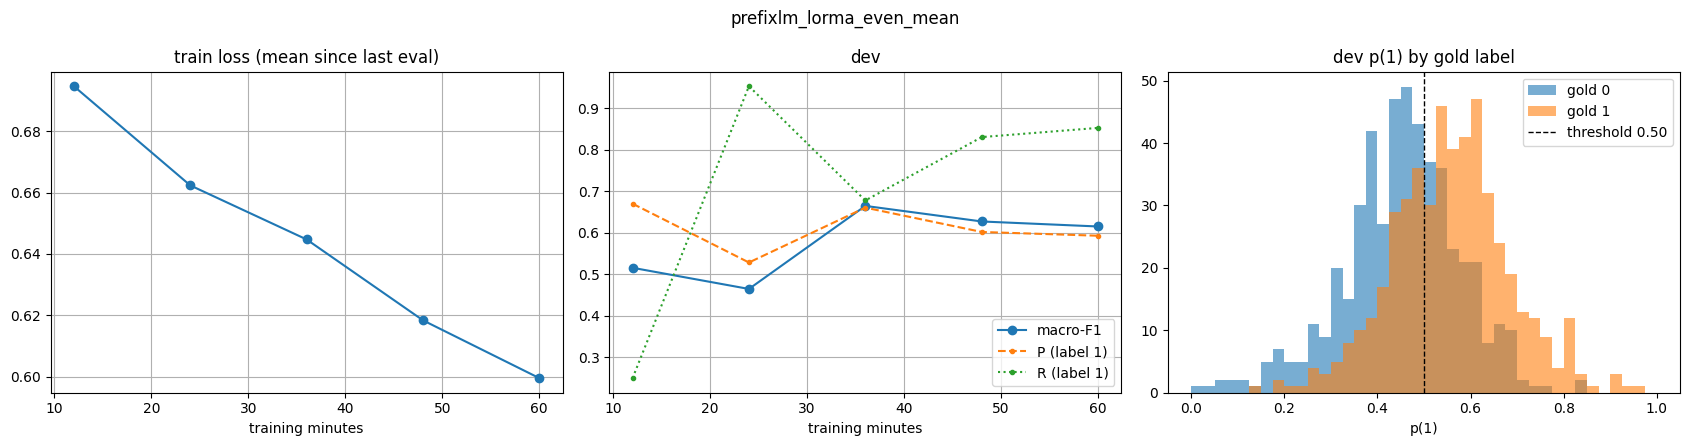

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

{
 "run": "prefixlm_lorma_even_mean",
 "params_total": 109826306,
 "params_trainable": 296450,
 "params_final": 109531394,
 "train_minutes": 60.00959821542104,
 "peak_gpu_gb": 3.605502464,
 "peak_infer_gb": 1.31828736,
 "best": {
  "F1": 0.6649326275703106,
  "epoch": 1,
  "step": 1904
 },
 "dev": {
  "F1": 0.6649326275703106,
  "P": 0.6607843137254902,
  "R": 0.6780684104627767,
  "n": 994
 },
 "threshold": 0.5
}


In [15]:
train_predict_seconds = 0.0
if SAVE_TRAIN_SCORES:
    seen = [k for k in TRAIN_KEYS if k in SEEN]
    if TRAIN_SCORES_MAX_DOCS and len(seen) > TRAIN_SCORES_MAX_DOCS:
        pick = set(np.random.default_rng(SEED).choice(len(seen), TRAIN_SCORES_MAX_DOCS, replace=False).tolist())
        seen = [k for i, k in enumerate(seen) if i in pick]
    t0 = time.time(); TL, _ = predict_logits(model, seen); train_predict_seconds = time.time() - t0
    LP = torch.from_numpy(TL).log_softmax(-1).numpy()
    json.dump({k: [round(float(a), 4), round(float(b), 4)] for (_, k), (a, b) in zip(seen, LP)},
              open(f"{RUN_DIR}/train_scores.json", "w"))
    print(f"train_scores.json: {len(seen)} documents ({train_predict_seconds:.0f}s)")

info = {
    "run": RUN_NAME, "arch": ARCH, "method": METHOD, "chunk_select": CHUNK_SELECT, "doc_pool": DOC_POOL,
    "attn": ATTN, "bart_mode": BART_MODE, "p1_repo": P1_REPOS[ARCH], "layers": STUDENT_LAYERS if STUDENT else "all",
    "kept_blocks": model.kept, "n_train_docs": len(TRAIN_KEYS), "n_seen_docs": len(SEEN),
    "config": {k: globals()[k] for k in ("SEED", "TRAIN_MAX_DOCS", "CHUNK_LEN", "CHUNK_STRIDE", "MAX_CHUNKS",
                                         "MAX_CHUNKS_PRED", "POOL", "CHUNK_POS", "POS_BUCKETS", "ATT_HIDDEN",
                                         "GRU_HIDDEN", "HEAD", "HEAD_HIDDEN", "EPOCHS", "MAX_TRAIN_MINUTES",
                                         "EVAL_EVERY_MINUTES", "PATIENCE", "BATCH_DOCS", "GRAD_ACCUM", "GRAD_CKPT",
                                         "LR", "HEAD_LR", "LAYER_LR_DECAY", "WEIGHT_DECAY", "WARMUP_FRAC", "GRAD_CLIP",
                                         "DROPOUT", "CLASS_WEIGHTS", "THRESHOLD", "PARTIAL_TOP", "UNFREEZE_FRAC",
                                         "UNFREEZE_EMBED", "BITFIT_ADD_BIAS", "ADAPT_TARGETS", "RANK", "ALPHA",
                                         "LORMA_VARIANT", "ADALORA_INIT_R", "ADALORA_TARGET_R", "ADALORA_TINIT",
                                         "ADALORA_TFINAL", "ADALORA_DELTA_T", "ADALORA_BETAS", "ADALORA_ORTH",
                                         "ADAPTER_AT", "ADAPTER_DIM", "ADAPTER_TRAIN_NORMS", "TEACHER_RUN",
                                         "STUDENT_LAYERS", "KD_T", "KD_ALPHA", "TRAIN_SCORES_MAX_DOCS")},
    "params_total": TOTAL_PARAMS, "params_trainable": TRAINABLE_PARAMS, "params_final": FINAL_PARAMS,
    "adalora_ranks": ADALORA_RANKS or None, "train_minutes": train_seconds / 60, "peak_gpu_gb": PEAK_TRAIN_GB,
    "peak_infer_gb": PEAK_INFER_GB, "best": best, "stop": stop, "threshold": THR,
    "dev_predict_seconds": dev_seconds, "test_predict_seconds": test_seconds,
    "train_predict_seconds": train_predict_seconds,
    "dev": {m: dev[m] for m in ("F1", "P", "R", "n")}, "dev_at_0.5": {m: dev_at_05[m] for m in ("F1", "P", "R")},
    "dev_per_class": dev["per_class"], "dev_confusion": dev["confusion"], "dev_attn_by_position": ATTN_BY_POS,
    "teacher": teacher_info and {"run": TEACHER_RUN, "arch": teacher_info["arch"], "method": teacher_info["method"],
                                 "params": teacher_info["params_final"], "dev_F1": teacher_info["dev"]["F1"],
                                 "dev_predict_seconds": teacher_info["dev_predict_seconds"]},
    "history": history,
}
json.dump(info, open(f"{RUN_DIR}/run_config.json", "w"), indent=1)
if SAVE_WEIGHTS:
    torch.save(model.state_dict(), f"{RUN_DIR}/model.pt")

import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
tm = [h["train_minutes"] for h in history]
ax[0].plot(tm, [h["train_loss"] for h in history], marker="o"); ax[0].set_title("train loss (mean since last eval)")
ax[1].plot(tm, [h["dev_F1"] for h in history], marker="o", label="macro-F1")
ax[1].plot(tm, [h["dev_P"] for h in history], marker=".", ls="--", label="P (label 1)")
ax[1].plot(tm, [h["dev_R"] for h in history], marker=".", ls=":", label="R (label 1)")
ax[1].set_title("dev"); ax[1].legend()
for a in ax[:2]: a.set_xlabel("training minutes"); a.grid(True)
for c in (0, 1):
    ax[2].hist(DEV_P1[DEV_Y == c], bins=40, range=(0, 1), alpha=0.6, label=f"gold {c}")
ax[2].axvline(THR, color="k", ls="--", lw=1, label=f"threshold {THR:.2f}")
ax[2].set_xlabel("p(1)"); ax[2].set_title("dev p(1) by gold label"); ax[2].legend()
fig.suptitle(RUN_NAME); plt.tight_layout(); plt.savefig(f"{RUN_DIR}/curves.png", dpi=130); plt.show()

api.create_repo(P4_REPO, private=True, exist_ok=True)
hub_push(lambda: api.upload_folder(folder_path=RUN_DIR, path_in_repo=f"runs/{RUN_NAME}", repo_id=P4_REPO,
                                   commit_message=f"{RUN_NAME} dev F1 {dev['F1']:.4f}"), f"runs/{RUN_NAME}")
try:
    from google.colab import files
    files.download(ZIP)
except Exception:
    pass
print(json.dumps({k: info[k] for k in ("run", "params_total", "params_trainable", "params_final", "train_minutes",
                                       "peak_gpu_gb", "peak_infer_gb", "best", "dev", "threshold")}, indent=1))

## All Phase-4 runs so far (from `cs781-p4`, every account)
A table of the saved runs and a mechanical count against the §10.2 requirements (which Phase-1 models and which
techniques have runs). Counts only — whether two runs are "substantially different" is your judgement.

In [16]:
P4_TECHNIQUES = set(METHODS)                                  # every METHOD here is on the §10.2.1 list
runs = sorted({f.split("/")[1] for f in api.list_repo_files(P4_REPO) if f.startswith("runs/") and f.endswith("/run_config.json")})
rows = []
for r in runs:
    try:
        rows.append(json.load(open(hf_hub_download(P4_REPO, f"runs/{r}/run_config.json", token=HF_TOKEN, force_download=True))))
    except Exception as e:
        print(f"  !! {r}: {e!r}")
print(f"{'run':40s} {'arch':11s} {'method':8s} {'select':10s} {'pool':5s} {'params':>7s} {'trainable':>10s} "
      f"{'dev F1':>7s} {'P':>7s} {'R':>7s} {'train min':>9s} {'dev inf s':>9s}")
for x in rows:
    dv = x["dev"]
    print(f"{x['run'][:40]:40s} {x['arch']:11s} {x['method']:8s} {x['chunk_select']:10s} {x['doc_pool']:5s} "
          f"{x['params_final']/1e6:6.1f}M {x['params_trainable']/1e6:9.3f}M {dv['F1']:7.4f} {dv['P']:7.4f} {dv['R']:7.4f} "
          f"{x['train_minutes']:9.1f} {x['dev_predict_seconds']:9.1f}")
archs = {x["arch"] for x in rows}; methods = {x["method"] for x in rows}
print(f"\nPhase-1 models with runs: {sorted(archs)}  (missing: {sorted({'llama', 'bart', 'prefixlm', 'mistral_swa'} - archs)})")
print(f"§10.2.1 techniques with runs: {sorted(methods & P4_TECHNIQUES)}  (non-KD: {len(methods & P4_TECHNIQUES - {'kd'})})  "
      f"LoRMA: {'lorma' in methods}  KD: {'kd' in methods}")

run_config.json:   0%|          | 0.00/4.22k [00:00<?, ?B/s]

run_config.json:   0%|          | 0.00/3.97k [00:00<?, ?B/s]

run_config.json:   0%|          | 0.00/3.99k [00:00<?, ?B/s]

run                                      arch        method   select     pool   params  trainable  dev F1       P       R train min dev inf s
bart_lorma_even_mean                     bart        lorma    even       mean    67.9M     0.149M  0.5999  0.6647  0.4467      56.5      25.1
llama_lorma_even_mean                    llama       lorma    even       mean   109.5M     0.296M  0.6012  0.6760  0.4366      60.0      64.6
prefixlm_lorma_even_mean                 prefixlm    lorma    even       mean   109.5M     0.296M  0.6649  0.6608  0.6781      60.0      66.6

Phase-1 models with runs: ['bart', 'llama', 'prefixlm']  (missing: ['mistral_swa'])
§10.2.1 techniques with runs: ['lorma']  (non-KD: 1)  LoRMA: True  KD: False
